## Data Labeling

In [1]:
import os
import numpy as np
import pandas as pd 
import seaborn as sn 
import matplotlib.pyplot as plt 

In [ ]:
!git clone https://github.com/https-deeplearning-ai/MLEP-public.git

## Load dataset function

In [2]:
def load_labeled_spam_dataset():
    """Load the 5 csv datasets in the dataset path"""

    base_path = "./data/youtube+spam+collection"

    csv_files = [os.path.join(base_path, csv) for csv in os.listdir(base_path)]

    dfs = [pd.read_csv(filename) for filename in csv_files]

    df = pd.concat(dfs)

    df = df.rename(columns={"CONTENT": "text", "CLASS": "label"})

    df = df.sample(frac=1, random_state=423)

    return df.reset_index()



## Inspect the final dataset

In [4]:
project_root = os.getcwd()
while not os.path.isdir(os.path.join(project_root, "data", "youtube+spam+collection")):
    parent = os.path.dirname(project_root)
    if parent == project_root:
        raise FileNotFoundError("No se encontró la carpeta data/youtube+spam+collection en el directorio actual ni en sus directorios superiores.")
    project_root = parent

os.chdir(project_root)

In [5]:
df_labeled = load_labeled_spam_dataset()
df_labeled.head(5)

,index,COMMENT_ID,AUTHOR,DATE,text,label
0,349,z120e5uautvcuper304ccf4bjrjugdpbwrc0k,moaz adnan,2015-06-05T20:01:23,who is going to reach the billion first : katy...,0
1,255,z12ts1xbpzv4sfrsd23rfbjourjgcj5mo,Gema LR,2014-11-08T03:26:51,With the korean girl more slut and bitch : Hyu...,0
2,49,z13df5jp4umzg3jhw04chniaxlviirc4hqs0k,Tominke Urbančok,2015-05-26T12:29:11.663000,Very Nice !!!<br />Yeah Fucking.﻿,0
3,110,z13xxf3qlq2bxpm1o22zidpqbn2tfpcjr04,Connor Mire,2015-05-21T20:46:54.704000,This Song is AWESOME!!!!﻿,0
4,252,z12tzpcjazigvrodo22dubixisqhfxtuo,twe enyss,2015-05-23T16:41:29.823000,"I love this-the talents of eminem and Skylar,w...",0


## Inspect data balanced

Value counts for each class:
 label
1    1005
0     951
Name: count, dtype: int64


<Axes: title={'center': 'Proportion of each class'}, ylabel='count'>

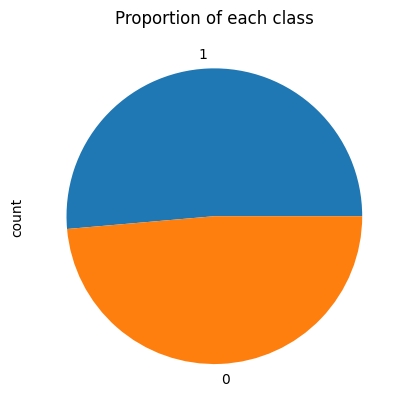

In [6]:
print(f'Value counts for each class:\n {df_labeled.label.value_counts()}')
df_labeled.label.value_counts().plot.pie(y="label", title="Proportion of each class")

## Cleaning the dataset

In [7]:
df_labeled = df_labeled.drop(["index", "COMMENT_ID", "AUTHOR", "DATE"], axis=1)

In [8]:
df_labeled.head(5)

,text,label
0,who is going to reach the billion first : katy...,0
1,With the korean girl more slut and bitch : Hyu...,0
2,Very Nice !!!<br />Yeah Fucking.﻿,0
3,This Song is AWESOME!!!!﻿,0
4,"I love this-the talents of eminem and Skylar,w...",0


##### Now are dataset only include relevant information

## Splitting the dataset

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X = df_labeled.drop(columns="label")
y = df_labeled["label"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.8, stratify=y)

In [12]:
print(f'There are {X_train.shape[0]} comments for training and {X_test.shape[0]} for testing')

There are 1564 comments for training and 392 for testing


#### Check if the stratification worked as expected

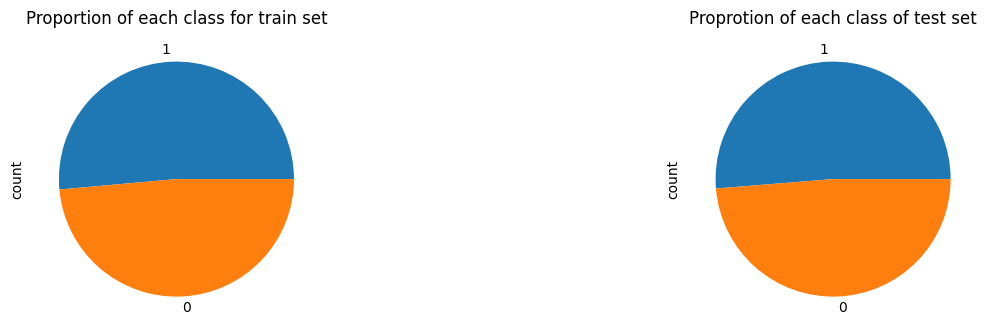

In [13]:
plt.subplot(1, 3, 1)
y_train.value_counts().plot.pie(y='label', title='Proportion of each class for train set', figsize=(10,6))
plt.subplot(1, 3, 3)
y_test.value_counts().plot.pie(y="label", title="Proprotion of each class of test set")
plt.tight_layout()
plt.show()

## Data Labeling

#### Establishing oerformance lower and upper bounds for reference + Text Encoding with CountVectorizer

##### To properly compare different label strategies, we need to establish a baseline for model accuracy. In this case, we will establish both a lower and an upper bound to compare different strategies against.

CountVectorizer is a handly tool included in sklearn ecosystem to encode text-based data

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(ngram_range=(1, 5))

#### Now that the text encoding is defined, we will select the Multinomial Naive Bayes classifier. This model is well suited for text classification and is fairly quick to train.
We will define a function to handle model fitting and print out the accuracy on the test data

In [15]:
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB

def calculate_accuracy(X_tr, y_tr, X_te = X_test, y_te = y_test, clf=MultinomialNB(), vectorizer=vectorizer):

    X_train_vect = vectorizer.fit_transform(X_tr.text.tolist())

    clf.fit(X_train_vect, y_tr)

    X_test_vect = vectorizer.transform(X_te.text.tolist())

    preds = clf.predict(X_test_vect)

    acc = accuracy_score(preds, y_te)

    return acc

#### Next, create a dictionary to store the accuracy of each labeling method

In [16]:
# Empty dictionary
accs = dict()

### RANDOM LABELING

In [17]:
rnd_labels = np.random.randint(0,2, X_train.shape[0])
acc = calculate_accuracy(X_train, rnd_labels)
acc

0.4719387755102041

In [18]:
rnd_accs = []

for _ in range(10):
    rnd_labels = np.random.randint(0, 2, X_train.shape[0])
    acc = calculate_accuracy(X_train, rnd_labels)
    rnd_accs.append(acc)

avg_acc = sum(rnd_accs)/len(rnd_accs)

accs["random-labeling"]=avg_acc

avg_acc

0.45510204081632655

In [19]:
print(f'The average accuracy for random labels is {avg_acc*100:.2f}%')

The average accuracy for random labels is 45.51%


### GROUND TRUTH VALUES

In [20]:
true_acc = calculate_accuracy(X_train, y_train)
accs["ground-truth"]=true_acc

print(f'The ground truth label accuracy is {true_acc}')

The ground truth label accuracy is 0.8877551020408163


#### Ground truth labeling produced a boost in accuracy. This result is expected, as the classifier can now properly identify patterns in the training data echich were lacking with randomly generated labels

### AUTOMATIC LABELING - TRYING OUT DIFFERENT LABEL STRATEGIES

#### Suppose we don´t have access to the true labels for this dataste - a common situation in ML. It´s natural to assume that there are patterns in the data that can provide clues about the correct labels. These patterns are dependent on the kind of data we are working with; to even hypothesize which patterns exist usually requires great domain knowledge.

#### For this particular dataste, we can likely come up with some useful rules that might help distinguish a spam Youtube comment from non-spam. 

#### `SPAM` is represented by 1 
#### `NOT SPAM` is represented by 0
#### `NO_LABEL` by -1'
We will use the `NO_LABEL` keyword when the rules we come up with don't apply to some data points. In those cases, it is better to avoid giving a label rather than guessing, which we already saw yields poor results.

## First iteration - Define some rules

#### For this first iteration, we will create three rules based on intuition about common patterns that appear in spam comments.

#### - `free` - promoting free stuff
#### - `subs` - ask users to suscribe
#### - `http` - include links

In [21]:
def labeling_rules_1(x):
    x = x.lower()

    rules = [
        "free" in x,
        "subs" in x,
        "http" in x
    ]

    if any(rules):
        return 1

    return -1

## Second iteration - Define some more other rules

#### New set of rules looking more promising, as it includes more patterns to classify as SPAM as well as some patterns to classify as NOT_SPAM. These improved rules should result in more data points with a label (as opposed to NO_LABEL).

In [22]:
def labeling_rules_2(x):
    x = x.lower()

    not_spam_rules = [
        "view" in x,
        "song" in x
    ]

    spam_rules = [
        "free" in x,
        "subs" in x,
        "gift" in x,
        "follow" in x,
        "http" in x
    ]

    if any(not_spam_rules):
        return 0

    if any(spam_rules):
        return 1

    return -1

In [23]:
labels = [labeling_rules_1(label) for label in X_train.text]
labels = np.asarray(labels)
labels

array([ 1, -1, -1, ..., -1, -1, -1], shape=(1564,))

#### New set of rules looking more promising, as it includes more patterns to classify as SPAM as well as some patterns to classify as NOT_SPAM. These improved rules should result in more data points with a label (as opposed to NO_LABEL).

In [ ]:
def label_given_rules(df, rules_function, name, acc_dict=accs, verbose=True):

    # Apply labeling rules to the comments 
    labels = [rules_function(label) for label in df.text]

    # Convert to a numpy array
    labels = np.asarray(labels)

    # Save initial number of data points
    initial_size = labels.shape[0]

    # Trim points with NO_LABEL label
    X_train_al = df[labels!=-1]
    labels = labels[labels!=-1]

    final_size = labels.shape[0]

    acc = calculate_accuracy(X_train_al, labels)

    if verbose:
        print(f'Proportion of data points kept: {final_size/initial_size*100:.2f}')
        print(f'Name labeling has an accuracy of {acc*100:.2f}%\n')

    acc_dict[name]=acc

    return X_train_al, labels, acc



## Third iteration - Even more rules

#### The rules you have defined so far are doing a fair job. Now, you'll add two additional rules: one each for classifying SPAM and NOT_SPAM comments.

### At a glance, it looks like NOT_SPAM comments are usually shorter, possibly because they don't include hyperlinks or because in general they tend to be more concrete (such as "I love this song!").

### Take a look at the average number of characters for SPAM comments vs NOT_SPAM ones:

In [26]:
from statistics import mean

print(f'NOT_SPAM comments have an average of {mean([len(t) for t in df_labeled[df_labeled.label==0].text]):.2f} characters')
print(f'SPAM comments have an average of {mean([len(t) for t in df_labeled[df_labeled.label==0].text]):.2f} characters')

NOT_SPAM comments have an average of 49.64 characters
SPAM comments have an average of 49.64 characters


#### It sure looks like there is a big difference in the number of characters for both types of comments.

#### To decide on a threshold to classify as NOT_SPAM, you can plot a histogram of the number of characters in NOT_SPAM comments:

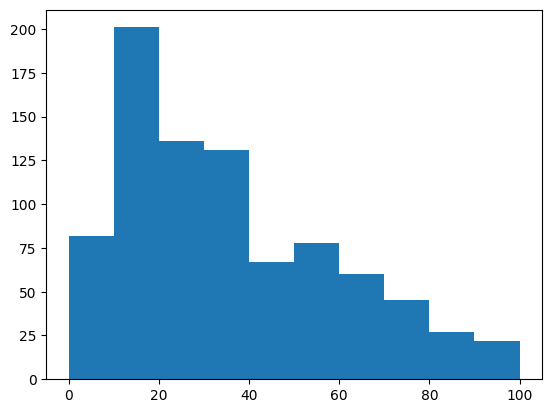

In [29]:
plt.hist([len(t) for t in df_labeled[df_labeled.label==0].text], range=(0,100))
plt.show()

#### The majority of NOT_SPAM comments have 30 characters or fewer, so you'll use 30 as your threshold.
#### Another prevalent pattern in spam comments is to ask users to "check out" a channel, website, or link.

In [30]:
def labeling_rules_3(x):
    
    # Convert text to lowercase
    x = x.lower()
    
    # Define list of rules to classify as NOT_SPAM
    not_spam_rules = [
        "view" in x,
        "song" in x,
        len(x) < 30
    ]
    

    # Define list of rules to classify as SPAM
    spam_rules = [
        "free" in x,
        "subs" in x,
        "gift" in x,
        "follow" in x,
        "http" in x,
        "check out" in x
    ]
    
    # Classify depending on the rules
    if any(not_spam_rules):
        return 0
    
    if any(spam_rules):
        return 1
    
    return -1

In [37]:
label_given_rules(X_train, labeling_rules_3, "third-iteration")

Proportion of data points kept: 78.45
Name labeling has an accuracy of 87.50%



(                                                   text
 687   EVERYONE PLEASE SUBSCRIBE TO MY CHANNEL OR CAN...
 1018  Dress like Rihanna at kpopcity.net - The large...
 605                                  LOVE THIS SONG!!!﻿
 1752                                 old and good song﻿
 659   Hello everyone, It Is not my intention to spam...
 ...                                                 ...
 462   Terrance. .thank you for serving our country. ...
 196                   Check out this video on YouTube:﻿
 770                                     Good times ...﻿
 1513                                               ;-)﻿
 1695  Hey guys love this but check out this girl nam...
 
 [1227 rows x 1 columns],
 array([1, 1, 0, ..., 0, 0, 1], shape=(1227,)),
 0.875)

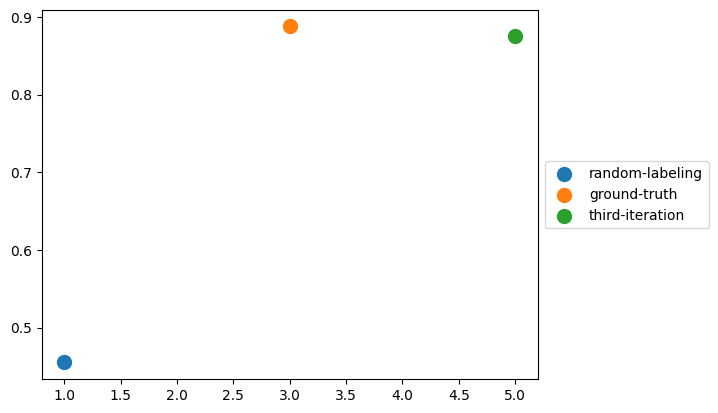

In [39]:
def plot_accuracies(accs=accs):
    colors = list("rgbcmy")
    items_num = len(accs)
    cont = 1

    for x, y in accs.items():
        if x in ['true-labels', 'random-labels', 'true-labels-best-clf']:
            plt.hlines(y, 0, (items_num-2)*2, colors=colors.pop())
        else:
            plt.scatter(cont, y, s=100)
            cont+=2
    plt.legend(accs.keys(), loc="center left",bbox_to_anchor=(1, 0.5))
    plt.show()
    
plot_accuracies()

In [ ]:
# Check SPAM comments
df_labeled [df_labeled.label==1]

Proportion of data points kept: 78.45
Name labeling has an accuracy of 85.46%



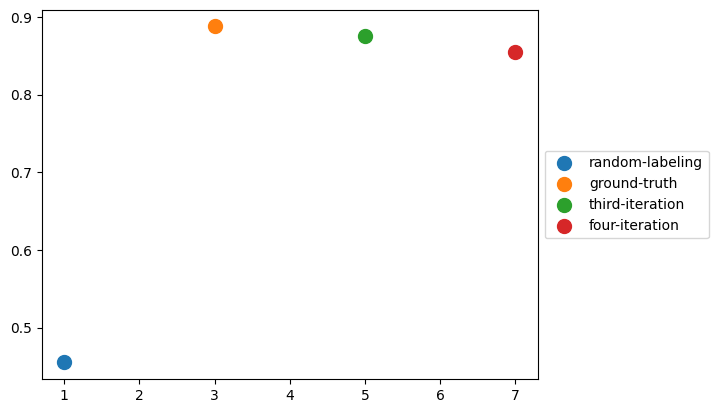

In [40]:
def labeling_rules_4(x):
    x = x.lower()

    not_spam_rules = [
        "view" in x,
        "song" in x,
        len(x) < 30
    ]

    spam_rules = [
        "free" in x,
        "subs" in x,
        "gift" in x,
        "follow" in x,
        "http" in x,
        "check out" in x
    ]

    # Prioritize clear spam indicators
    if any(spam_rules):
        return 1

    if any(not_spam_rules):
        return 0

    return -1


try:
    label_given_rules(X_train, labeling_rules_4, "four-iteration")
    plot_accuracies()
    
except ValueError:
    print("You have not defined any rules.")

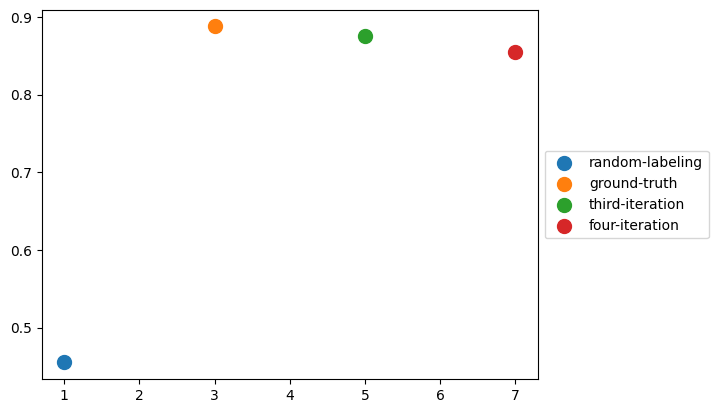

In [42]:
plot_accuracies()